# Red neuronal simple

(Ejercicio, 3 puntos posibles)

En este notebook programaremos una red neuronal simple utilizando numpy. El objetivo es que comprendamos la diferencia con el perceptrón. A diferencia del ejercicio anterior en este usaremos funciones de numpy.

- *numpy.dot(a, b, out=None)* Dot product of two arrays. Parameters: a array_like First argument, b array_like Second argument.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pibenitezq126/redes-neuronales-practicas/blob/main/notebooks/1_04_red_neuronal_simple.ipynb)

@juan1rving


In [1]:
# Cargamos paquetes
import numpy as np

### Función de activación

Para este ejemplo utilizaremos la función sigmoide como función de activación.

$$ f(x) = \frac{ 1 }{1 + e^{-x} } 


In [2]:
# TODO (1 punto): Implementar la función de activación sigmoide.
# Fórmula: sigma(h) = 1 / (1 + exp(-h))
def sigmoide(h):
    return 1 / (1 + np.exp(-h))


### Neurona simple

Implementación de la neurona simple mediante una clase.

In [3]:
# TODO (1 punto): Implementar la clase Neurona
class Neurona:
    def __init__(self, W, b, activacion):
        self.W = W
        self.b = b
        self.activacion = activacion

    def combinacion_lineal(self, X):
        # Suma ponderada: h = W · X + b
        return np.dot(self.W, X) + self.b

    def forward(self, X):
        # Propagación hacia adelante: f(h)
        h = self.combinacion_lineal(X)
        return self.activacion(h)


## Probar la red

Ahora definamos unos pesos y veamos el resultado de una pasada frontal (fordward pass).

In [4]:
# Definamos unos pesos y sesgo
inputs = np.array([0.7, -0.3])
pesos = np.array([0.1, 0.8])
sesgo = -0.1

clasificador_log = Neurona(pesos, sesgo, sigmoide)

# Hacemos una predicción
output = clasificador_log.forward(inputs)
print(f'Output: {output:.4f}')

Output: 0.4329


=== Comparación con la entrada de prueba ===
Combinación lineal h = W · X + b: -0.2700
Salida con Sigmoide: 0.4329  (Comprobación esperada: 0.4329)
Salida con Tanh:     -0.2636 (Comprobación esperada: -0.2636)

=== Valores en puntos clave (Pizarra de clase) ===
 h   | Sigmoide (0 a 1) | Tanh (-1 a 1)
--------------------------------------
-3.0 |           0.0474 |       -0.9951
-1.0 |           0.2689 |       -0.7616
 0.0 |           0.5000 |        0.0000
 1.0 |           0.7311 |        0.7616
 3.0 |           0.9526 |        0.9951


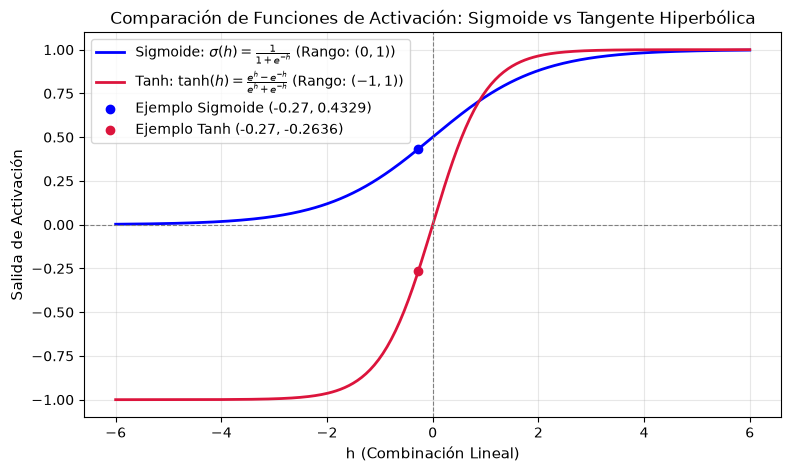


--- Conclusiones de la Comparación ---
1. Rango de salida: Sigmoide acota entre (0, 1), ideal para probabilidades. Tanh acota entre (-1, 1).
2. Centrado en cero: Tanh está centrada en 0 (tanh(0) = 0), lo que evita sesgos unidireccionales en el gradiente.
3. Magnitud de gradientes: La derivada de Tanh (max 1.0 en 0) es 4 veces mayor que la de la Sigmoide (max 0.25 en 0),
   lo que ayuda a mitigar el problema del desvanecimiento del gradiente (vanishing gradient).


In [5]:
# TODO: (1 punto) Define una función de activación tangente hiperbólica. Muestra sus salidas y compara con la función sigmoide.
import matplotlib.pyplot as plt

# 1. Definición de la función tangente hiperbólica
def tangente_hiperbolica(h):
    return np.tanh(h)

# 2. Evaluación con los mismos pesos, sesgo y entrada del ejemplo anterior
clasificador_tanh = Neurona(pesos, sesgo, tangente_hiperbolica)
output_tanh = clasificador_tanh.forward(inputs)

h_ejemplo = clasificador_log.combinacion_lineal(inputs)
print("=== Comparación con la entrada de prueba ===")
print(f"Combinación lineal h = W · X + b: {h_ejemplo:.4f}")
print(f"Salida con Sigmoide: {output:.4f}  (Comprobación esperada: 0.4329)")
print(f"Salida con Tanh:     {output_tanh:.4f} (Comprobación esperada: -0.2636)")

# 3. Tabla comparativa con los valores analizados en la pizarra: h in [-3, -1, 0, 1, 3]
valores_h = np.array([-3.0, -1.0, 0.0, 1.0, 3.0])
sig_vals = sigmoide(valores_h)
tanh_vals = tangente_hiperbolica(valores_h)

print("\n=== Valores en puntos clave (Pizarra de clase) ===")
print(" h   | Sigmoide (0 a 1) | Tanh (-1 a 1)")
print("-" * 38)
for h_val, s_val, t_val in zip(valores_h, sig_vals, tanh_vals):
    print(f"{h_val:4.1f} | {s_val:16.4f} | {t_val:13.4f}")

# 4. Gráfica comparativa del comportamiento de ambas funciones
rango_h = np.linspace(-6, 6, 300)
plt.figure(figsize=(9, 5))
plt.plot(rango_h, sigmoide(rango_h), label=r'Sigmoide: $\sigma(h) = \frac{1}{1 + e^{-h}}$ (Rango: $(0, 1)$)', color='blue', linewidth=2)
plt.plot(rango_h, tangente_hiperbolica(rango_h), label=r'Tanh: $\tanh(h) = \frac{e^h - e^{-h}}{e^h + e^{-h}}$ (Rango: $(-1, 1)$)', color='crimson', linewidth=2)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.scatter([-0.27], [output], color='blue', zorder=5, label=f'Ejemplo Sigmoide (-0.27, {output:.4f})')
plt.scatter([-0.27], [output_tanh], color='crimson', zorder=5, label=f'Ejemplo Tanh (-0.27, {output_tanh:.4f})')
plt.title('Comparación de Funciones de Activación: Sigmoide vs Tangente Hiperbólica', fontsize=12)
plt.xlabel('h (Combinación Lineal)', fontsize=11)
plt.ylabel('Salida de Activación', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left', fontsize=10)
plt.show()

print("\n--- Conclusiones de la Comparación ---")
print("1. Rango de salida: Sigmoide acota entre (0, 1), ideal para probabilidades. Tanh acota entre (-1, 1).")
print("2. Centrado en cero: Tanh está centrada en 0 (tanh(0) = 0), lo que evita sesgos unidireccionales en el gradiente.")
print("3. Magnitud de gradientes: La derivada de Tanh (max 1.0 en 0) es 4 veces mayor que la de la Sigmoide (max 0.25 en 0),")
print("   lo que ayuda a mitigar el problema del desvanecimiento del gradiente (vanishing gradient).")
